# AR(3): inside a badly failed coefficient recovery

Inspect the **earlier random-start failure**, rather than search for a new case after seeing its results. The generating coefficients are $(0.5,-0.2,0.1)$; the returned coefficients are about $(27.49,-14.01,4.05)$. The same path also has a successful zero-coefficient start, which provides a paired control.

Keep the supplied sphere descent and strict best-width tracking unchanged. Record the current direction, the best direction, both coefficient vectors, the first coordinates, and the coefficient errors. The true coefficients are used only for diagnostics; no estimate, step, or start is selected using those errors.

Sources: [previous saved failure](outputs/csv/ar3_best_coefficient_tracking/summary.csv), [optimizer and coefficient tracker](ar_tools/descent.py), [simulator](ar_tools/functions.py). All displayed figures are saved automatically as PDF and PNG.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from threadpoolctl import threadpool_limits

AR_DIR=next(candidate.resolve()
    for root in (Path.cwd(),*Path.cwd().parents)
    for candidate in (root/'Code'/'Code_AR_processes',root)
    if (candidate/'ar_tools/functions.py').is_file())
PROJECT_ROOT=AR_DIR.parents[1]
if str(PROJECT_ROOT) not in sys.path:sys.path.insert(0,str(PROJECT_ROOT))
from Code.Code_AR_processes.ar_tools.descent import projected_subgradient_empirical_width
from Code.Code_AR_processes.ar_tools.functions import simulate_uniform_ar,sliding_window_point_cloud
from Code.Code_AR_processes.ar_tools.lp_widths import exact_empirical_width_low_dimension

EXPERIMENT='ar3_failed_coefficient_tracking'
DATA_DIR=AR_DIR/'outputs/csv'/EXPERIMENT
PDF_DIR=AR_DIR/'outputs/pdfs'/EXPERIMENT
IMAGE_DIR=AR_DIR/'outputs/images'/EXPERIMENT
for d in (DATA_DIR,PDF_DIR,IMAGE_DIR):d.mkdir(parents=True,exist_ok=True)
np.set_printoptions(precision=8,suppress=True)

def save_figure(fig,stem):
    fig.savefig(PDF_DIR/f'{stem}.pdf',bbox_inches='tight')
    fig.savefig(IMAGE_DIR/f'{stem}.png',dpi=160,bbox_inches='tight')
    plt.close(fig)
    display(Image(filename=str(IMAGE_DIR/f'{stem}.png')))

Matplotlib created a temporary cache directory at /var/folders/tr/kt47kz8d61ngpcfl5d_s9fc80000gn/T/matplotlib-rmxfln1s because the default path (/Users/iljasukhanov/.matplotlib) is not a writable directory; it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.
Matplotlib is building the font cache; this may take a moment.


## Reproduce the fixed failed run and its control

Reuse $T=1000$, burn-in 1000, process seed 20261018, optimizer seed 20261019 and the literal schedule $\gamma_t=0.1(0.997)^t$. Evaluate 5000 states, including the initial state at index 0. Disable patience stopping and use a strict width comparison, exactly as in [the preceding tracking notebook](ar3_coefficient_tracker.ipynb).

Recompute the global empirical-width reference using [exact_empirical_width_low_dimension](ar_tools/lp_widths.py), a floating-point difference-body hull calculation in dimension four. This reference diagnoses whether the failed search found the empirical minimum; it is not supplied to either descent. No exact-arithmetic certificate is claimed.

In [2]:
TRUE_PHI=np.array([.5,-.2,.1])
T,BURNIN=1000,1000
PROCESS_SEED,OPTIMIZER_SEED=20261018,20261019
GAMMA0,BETA,EVALUATIONS=.1,.997,5000
EARLY_LAST=80
series=simulate_uniform_ar(TRUE_PHI,T,burnin=BURNIN,rng=PROCESS_SEED)
points=sliding_window_point_cloud(series,4)
random_u=np.random.default_rng(OPTIMIZER_SEED).normal(size=4)
random_u/=np.linalg.norm(random_u)
starts={'Failed random start':random_u,'Zero-start control':np.array([1.,0.,0.,0.])}
with threadpool_limits(limits=1):
    global_width,global_direction,hull_vertices=exact_empirical_width_low_dimension(points)
if global_direction[0]<0:global_direction=-global_direction
global_phi=-global_direction[1:]/global_direction[0]
true_direction=np.r_[1.,-TRUE_PHI]
true_direction/=np.linalg.norm(true_direction)
true_direction_width=float(np.ptp(points@true_direction))
configuration=dict(true_phi=TRUE_PHI.tolist(),T=T,burnin=BURNIN,
    process_seed=PROCESS_SEED,optimizer_seed=OPTIMIZER_SEED,gamma0=GAMMA0,beta=BETA,
    evaluated_states=EVALUATIONS,patience='disabled',improvement_tolerance=0.,
    initial_directions={k:v.tolist() for k,v in starts.items()},
    case_selection='fixed failure already saved in ar3_best_coefficient_tracking',
    global_width=global_width,global_phi=global_phi.tolist(),global_direction=global_direction.tolist(),
    true_direction_width=true_direction_width,early_plot_last_iteration=EARLY_LAST)
(DATA_DIR/'configuration.json').write_text(json.dumps(configuration,indent=2)+'\n')
pd.DataFrame({'time':np.arange(T),'X_t':series}).to_csv(DATA_DIR/'process.csv',index=False)
print('Generating coefficients:',TRUE_PHI)
print('Global numerical reference:',global_width,'; associated coefficients:',global_phi)

Generating coefficients: [ 0.5 -0.2  0.1]
Global numerical reference: 1.7476115557459602 ; associated coefficients: [ 0.50066818 -0.20307294  0.10251497]


In [3]:
fits={}
frames=[]
rows=[]
with threadpool_limits(limits=1):
    for label,u0 in starts.items():
        settings=dict(points=points,initial_direction=u0,iterations=EVALUATIONS,
            initial_step=GAMMA0,step_schedule='geometric',geometric_decay=BETA,
            patience=EVALUATIONS+1,improvement_tolerance=0.,record_directions=True)
        result=projected_subgradient_empirical_width(**settings,record_best_coefficients=True)
        untracked=projected_subgradient_empirical_width(**settings)
        for key in ['width_history','best_width_history','direction_history','direction','step_history']:
            np.testing.assert_array_equal(result[key],untracked[key])
        directions=result['direction_history']
        updates=result['best_update_history']
        best_indices=np.maximum.accumulate(np.where(updates,np.arange(EVALUATIONS),0))
        best_directions=directions[best_indices]
        current_phi=-directions[:,1:]/directions[:,:1]
        best_phi=result['best_coefficient_history']
        np.testing.assert_array_equal(best_phi,-best_directions[:,1:]/best_directions[:,:1])
        np.testing.assert_array_equal(result['coefficients'],-result['direction'][1:]/result['direction'][0])
        assert np.all(np.diff(result['best_width_history'])<=0)
        # Direct algebra for unit directions, independently checked numerically.
        predicted_norm=np.sqrt(np.maximum(1-best_directions[:,0]**2,0))/abs(best_directions[:,0])
        np.testing.assert_allclose(np.linalg.norm(best_phi,axis=1),predicted_norm,atol=1e-12,rtol=1e-12)
        frame=pd.DataFrame(dict(
            start=label,iteration=np.arange(EVALUATIONS),best_updated=updates,
            current_width=result['width_history'],best_width=result['best_width_history'],
            width_gap=result['best_width_history']-global_width,
            step=result['step_history'],current_u0=directions[:,0],best_u0=best_directions[:,0],
            current_coefficient_error=np.linalg.norm(current_phi-TRUE_PHI,axis=1),
            best_coefficient_error=np.linalg.norm(best_phi-TRUE_PHI,axis=1),
            best_coefficient_norm=np.linalg.norm(best_phi,axis=1),
            reciprocal_abs_best_u0=1/abs(best_directions[:,0]),
            best_angle_to_global_degrees=np.degrees(np.arccos(np.clip(abs(best_directions@global_direction),0,1))),
        ))
        for j in range(4):
            frame[f'current_u_{j}']=directions[:,j]
            frame[f'best_u_{j}']=best_directions[:,j]
        for j in range(3):
            frame[f'current_phi_{j+1}']=current_phi[:,j]
            frame[f'best_phi_{j+1}']=best_phi[:,j]
        frames.append(frame)
        fits[label]=result
        final=frame.iloc[-1]
        rows.append(dict(start=label,minimum_width=result['minimum_width'],
            relative_width_gap_percent=100*(result['minimum_width']/global_width-1),
            phi_1=result['coefficients'][0],phi_2=result['coefficients'][1],phi_3=result['coefficients'][2],
            coefficient_error=final.best_coefficient_error,abs_best_u0=abs(final.best_u0),
            angle_to_global_degrees=final.best_angle_to_global_degrees,
            best_updates_after_initialization=int(updates.sum()-1),tracking_changes_search=False))
history=pd.concat(frames,ignore_index=True)
summary=pd.DataFrame(rows)
failure=history[history.start=='Failed random start'].reset_index(drop=True)
control=history[history.start=='Zero-start control'].reset_index(drop=True)
accepted=failure[failure.best_updated].copy()
accepted['coefficient_error_change']=accepted.best_coefficient_error.diff()
accepted['width_change']=accepted.best_width.diff()
accepted['u0_sign_change']=np.r_[False,np.sign(accepted.best_u0.to_numpy()[1:])!=np.sign(accepted.best_u0.to_numpy()[:-1])]
assert np.all(accepted.width_change.dropna()<0)
assert np.any(accepted.coefficient_error_change.dropna()>0)
previous=pd.read_csv(AR_DIR/'outputs/csv/ar3_best_coefficient_tracking/summary.csv')
previous_bad=previous[previous.start=='Earlier random direction'].iloc[0]
np.testing.assert_allclose(fits['Failed random start']['coefficients'],previous_bad[['phi_1','phi_2','phi_3']].to_numpy(dtype=float),rtol=0,atol=1e-10)
np.testing.assert_allclose(fits['Failed random start']['minimum_width'],previous_bad.minimum_width,rtol=0,atol=1e-12)
history.to_csv(DATA_DIR/'iteration_history.csv',index=False)
accepted.to_csv(DATA_DIR/'failed_best_updates.csv',index=False)
summary.to_csv(DATA_DIR/'summary.csv',index=False)
np.savez_compressed(DATA_DIR/'directions_and_coefficients.npz',
    failed_directions=fits['Failed random start']['direction_history'],
    failed_best_coefficients=fits['Failed random start']['best_coefficient_history'],
    control_directions=fits['Zero-start control']['direction_history'],
    global_direction=global_direction,global_phi=global_phi,true_phi=TRUE_PHI)
display(summary)
print('Reproduced the saved failure; tracking leaves all directions and widths exactly unchanged.')

Reproduced the saved failure; tracking leaves all directions and widths exactly unchanged.


,start,minimum_width,relative_width_gap_percent,phi_1,phi_2,phi_3,coefficient_error,abs_best_u0,angle_to_global_degrees,best_updates_after_initialization,tracking_changes_search
0,Failed random start,1.862952,6.599915e+00,27.493001,-14.014123,4.045696,30.578107,0.032114,59.520125,73,False
1,Zero-start control,1.747612,4.704631e-07,0.500668,-0.203073,0.102515,0.004027,0.876244,0.000008,68,False


## What happens at the accepted improvements?

The following landmarks are **diagnostics after fitting**, not alternative coefficient-selection rules. They include the smallest error among accepted best-width estimates, the largest error among those estimates, and the smallest error among *all visited* current estimates. In particular, a visited direction can have smaller coefficient error yet be rejected because its width is larger.

Our direct algebra explains the denominator effect. For a unit direction $u=(a,b)$ with $a\ne0$ and $\phi=-b/a$,
$$\|\phi\|=\frac{\sqrt{1-a^2}}{|a|},\qquad
D\phi(u)[\delta u]=-\frac{\delta b+\phi\,\delta a}{a}.$$
The first identity follows from $\|b\|^2=1-a^2$; the second is differentiation of the coordinate ratio. Thus a unit direction with small first coordinate has large recovered coefficients. These are our algebraic deductions for this diagnostic, and the norm identity is checked numerically in the preceding cell. The ratio is the one implemented in [descent.py](ar_tools/descent.py).

The width is even in $u$, so $u$ and $-u$ recover the same coefficients. A full sign flip is not itself a failure mechanism. The plots use the signed first coordinate to show passages across the coordinate singularity, and its absolute value when discussing the size of the denominator. This also follows directly from the width and ratio formulas in the implementation.

In [4]:
landmarks={
    'Initialization':0,
    'Lowest error among accepted best estimates (diagnostic)':int(failure.best_coefficient_error.idxmin()),
    'Largest accepted-estimate error / smallest accepted |u0|':int(failure.best_coefficient_error.idxmax()),
    'Lowest error among all visited current estimates (diagnostic)':int(failure.current_coefficient_error.idxmin()),
    'Last accepted width improvement':int(accepted.iteration.iloc[-1]),
    'End of recorded run':EVALUATIONS-1,
}
milestone_rows=[]
for event,index in landmarks.items():
    row=failure.iloc[index].to_dict()
    milestone_rows.append(dict(event=event,**row))
milestones=pd.DataFrame(milestone_rows)
milestones.to_csv(DATA_DIR/'diagnostic_milestones.csv',index=False)
display(milestones[['event','iteration','best_updated','current_width','best_width','best_u0',
                   'best_phi_1','best_phi_2','best_phi_3','best_coefficient_error','current_coefficient_error']])
print(f'{int((accepted.coefficient_error_change>0).sum())} of {len(accepted)-1} accepted width improvements increased the coefficient error.')
print('The closest visited estimate was not selected by coefficient error; it is shown only as a diagnostic.')

32 of 73 accepted width improvements increased the coefficient error.
The closest visited estimate was not selected by coefficient error; it is shown only as a diagnostic.


,event,iteration,best_updated,current_width,best_width,best_u0,best_phi_1,best_phi_2,best_phi_3,best_coefficient_error,current_coefficient_error
0,Initialization,0,True,3.005942,3.005942,0.046904,17.302497,-6.669389,-10.473086,20.879824,20.879824
1,Lowest error among accepted best estimates (di...,8,True,2.071422,2.071422,0.177574,4.636203,-2.919946,0.832403,5.004268,5.004268
2,Largest accepted-estimate error / smallest acc...,25,True,1.926193,1.926193,-0.005627,-159.086599,75.638887,-23.562768,178.267625,178.267625
3,Lowest error among all visited current estimat...,26,False,2.102997,1.926193,-0.005627,-159.086599,75.638887,-23.562768,178.267625,3.486295
4,Last accepted width improvement,4868,True,1.862952,1.862952,0.032114,27.493001,-14.014123,4.045696,30.578107,30.578107
5,End of recorded run,4999,False,1.862952,1.862952,0.032114,27.493001,-14.014123,4.045696,30.578107,30.578111


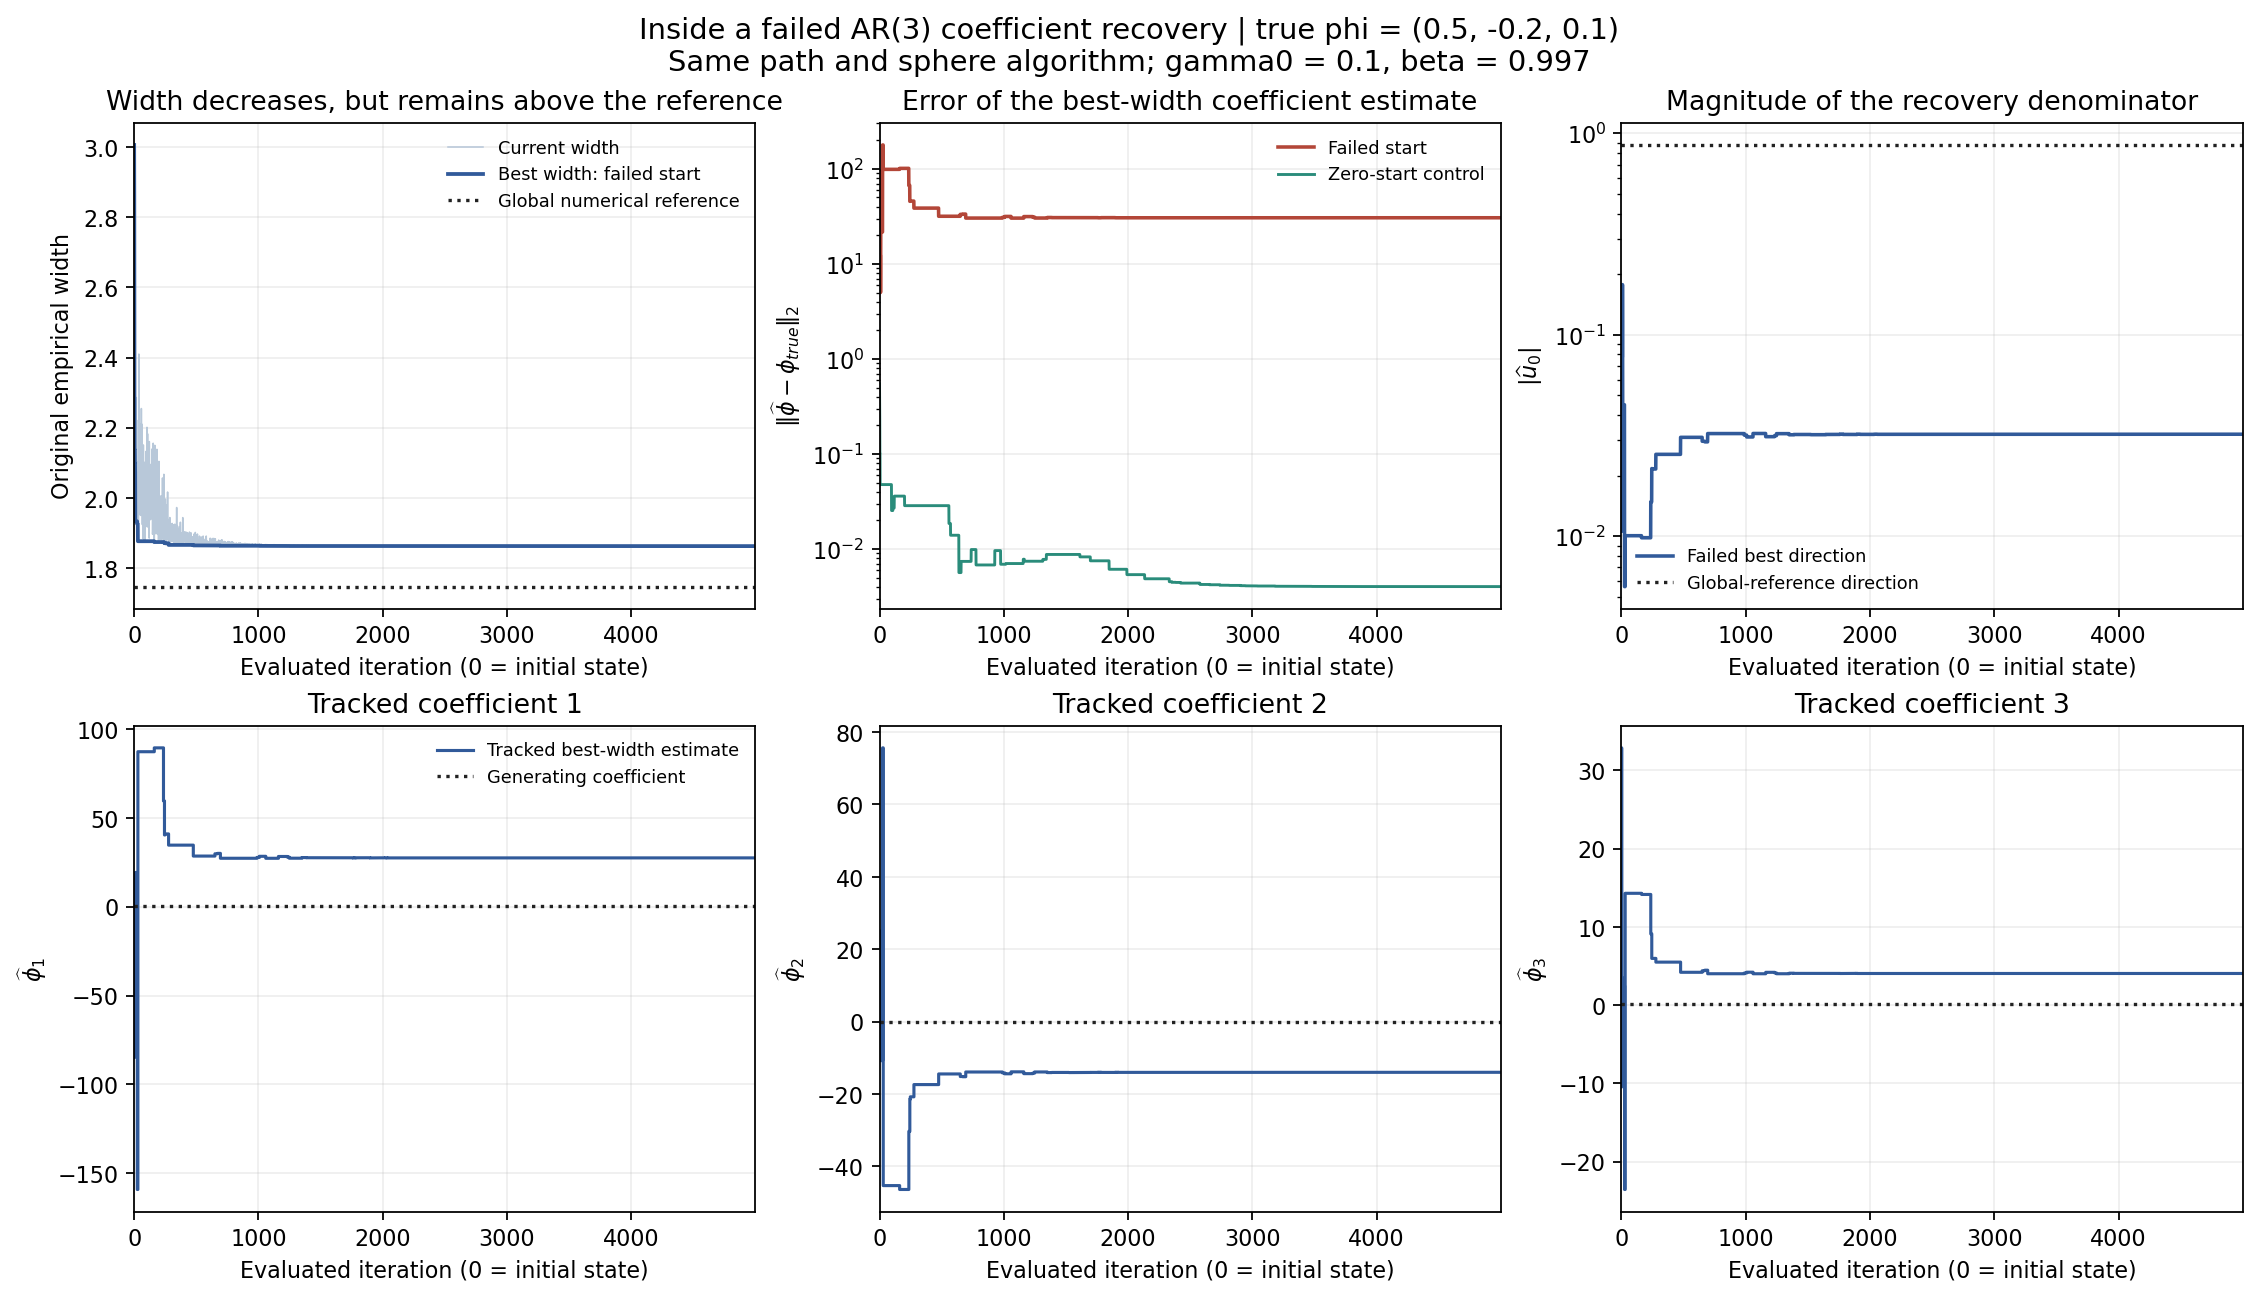

In [5]:
with plt.rc_context({'font.size':10,'pdf.fonttype':42}):
    fig,axes=plt.subplots(2,3,figsize=(14,8),constrained_layout=True)
    axes[0,0].plot(failure.iteration,failure.current_width,color='#b8c8d9',lw=.7,label='Current width')
    axes[0,0].plot(failure.iteration,failure.best_width,color='#315a9a',lw=1.7,label='Best width: failed start')
    axes[0,0].axhline(global_width,color='#222222',ls=':',label='Global numerical reference')
    axes[0,0].set(title='Width decreases, but remains above the reference',ylabel='Original empirical width')
    axes[0,0].legend(fontsize=8,frameon=False)
    axes[0,1].semilogy(failure.iteration,failure.best_coefficient_error,color='#b34638',lw=1.6,label='Failed start')
    axes[0,1].semilogy(control.iteration,control.best_coefficient_error,color='#2a8c7b',lw=1.3,label='Zero-start control')
    axes[0,1].set(title='Error of the best-width coefficient estimate',ylabel=r'$\|\widehat\phi-\phi_{true}\|_2$')
    axes[0,1].legend(fontsize=8,frameon=False)
    axes[0,2].semilogy(failure.iteration,abs(failure.best_u0),color='#315a9a',lw=1.6,label='Failed best direction')
    axes[0,2].axhline(abs(global_direction[0]),color='#222222',ls=':',label='Global-reference direction')
    axes[0,2].set(title='Magnitude of the recovery denominator',ylabel=r'$|\widehat u_0|$')
    axes[0,2].legend(fontsize=8,frameon=False)
    for j in range(3):
        ax=axes[1,j]
        ax.step(failure.iteration,failure[f'best_phi_{j+1}'],where='post',color='#315a9a',lw=1.4,label='Tracked best-width estimate')
        ax.axhline(TRUE_PHI[j],color='#222222',ls=':',label='Generating coefficient')
        ax.set(title=f'Tracked coefficient {j+1}',ylabel=rf'$\widehat\phi_{j+1}$')
    axes[1,0].legend(fontsize=8,frameon=False)
    for ax in axes.flat:
        ax.set(xlabel='Evaluated iteration (0 = initial state)',xlim=(0,EVALUATIONS-1))
        ax.grid(alpha=.2)
    fig.suptitle('Inside a failed AR(3) coefficient recovery | true phi = (0.5, -0.2, 0.1)\n'
                 'Same path and sphere algorithm; gamma0 = 0.1, beta = 0.997',fontsize=13)
    save_figure(fig,'01_full_failure_tracking')

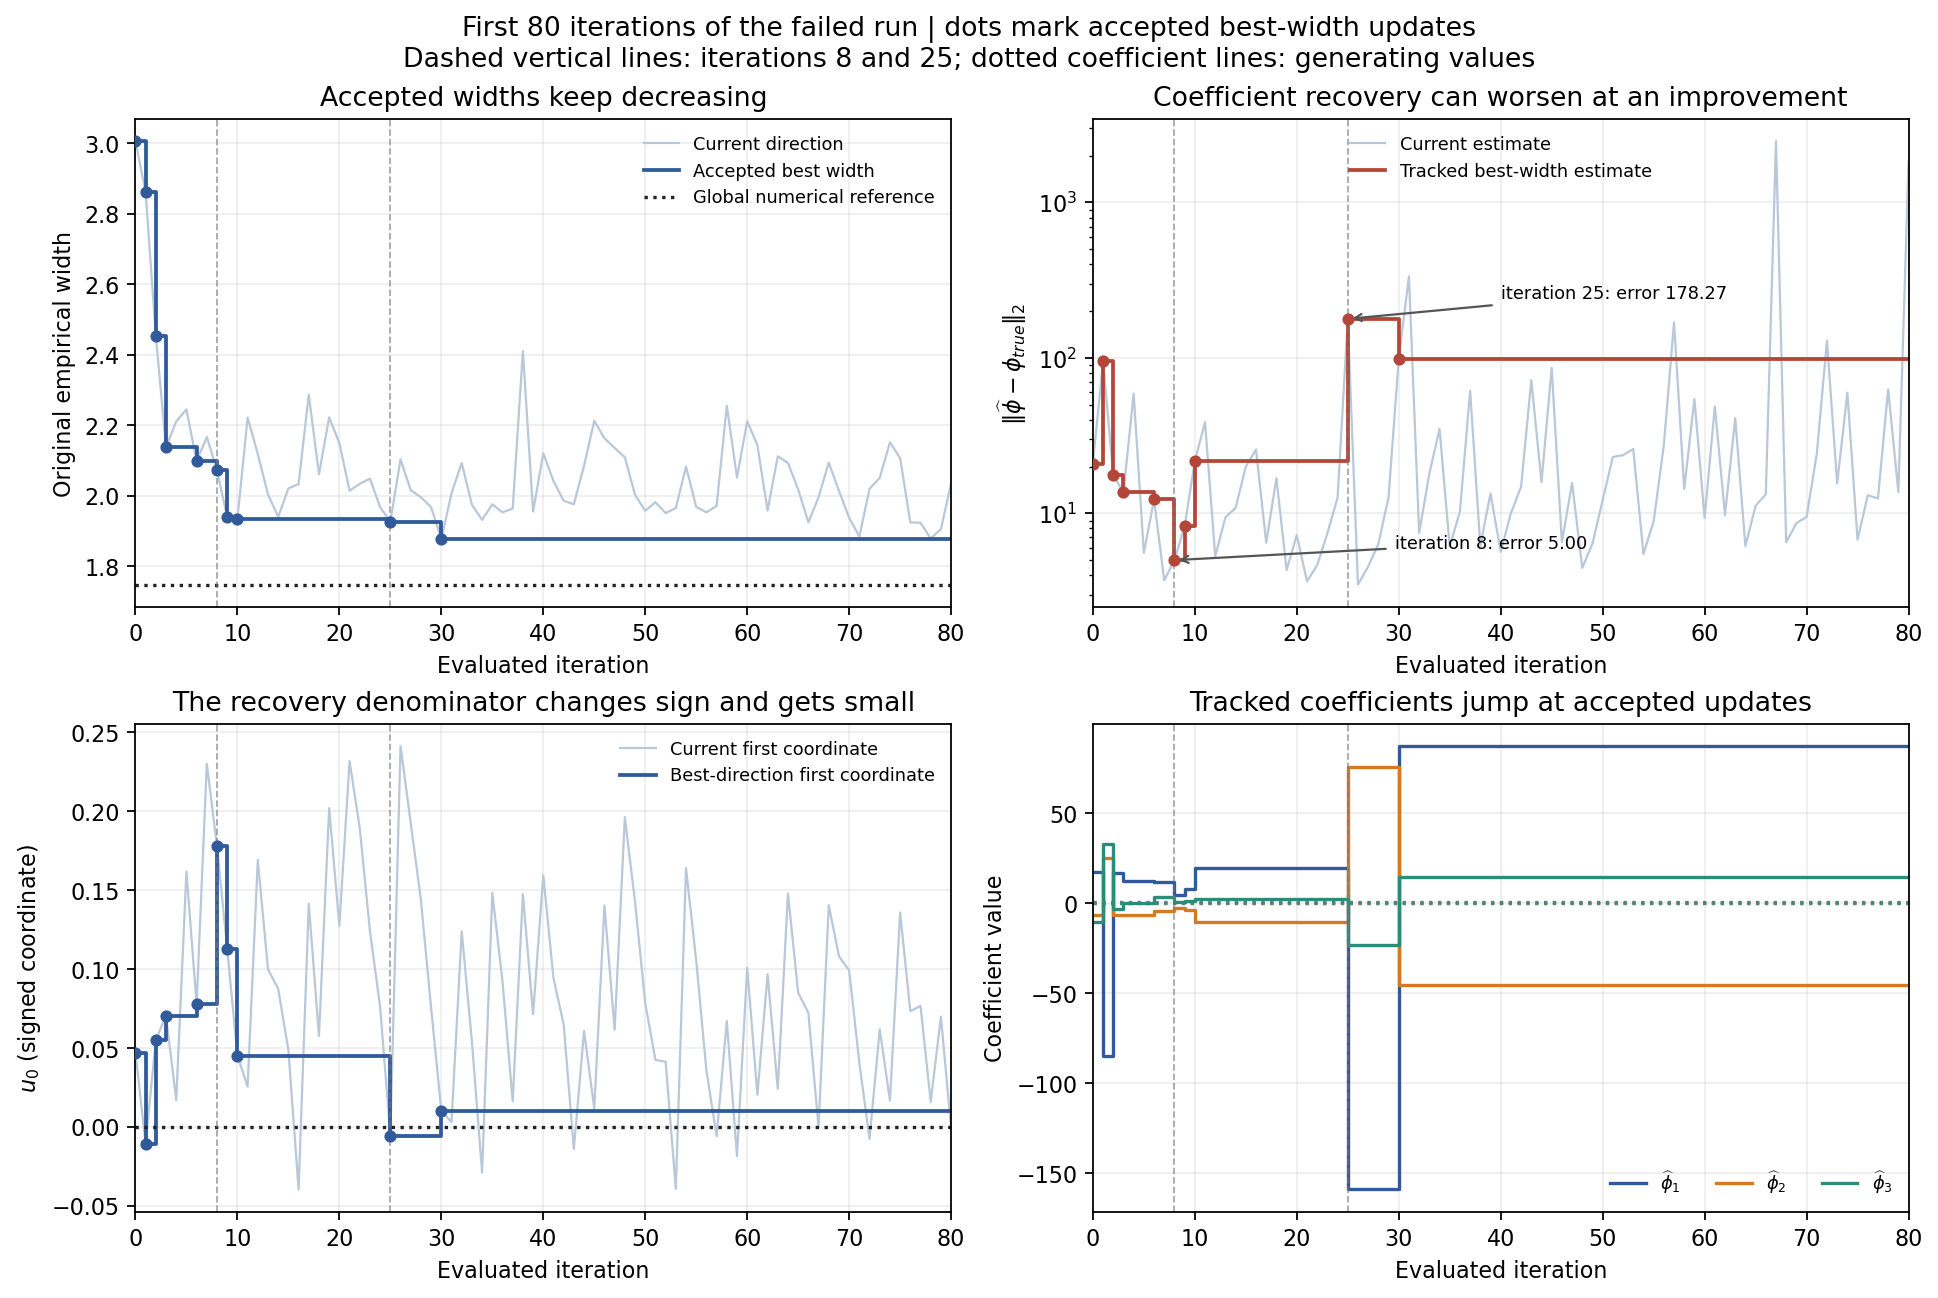

In [6]:
early=failure[failure.iteration<=EARLY_LAST]
early_updates=accepted[accepted.iteration<=EARLY_LAST]
max_index=int(failure.best_coefficient_error.idxmax())
best_index=int(failure.best_coefficient_error.idxmin())
with plt.rc_context({'font.size':10,'pdf.fonttype':42}):
    fig,axes=plt.subplots(2,2,figsize=(12,8),constrained_layout=True)
    axes[0,0].plot(early.iteration,early.current_width,color='#b8c8d9',lw=1,label='Current direction')
    axes[0,0].step(early.iteration,early.best_width,where='post',color='#315a9a',lw=1.7,label='Accepted best width')
    axes[0,0].scatter(early_updates.iteration,early_updates.best_width,color='#315a9a',s=20,zorder=4)
    axes[0,0].axhline(global_width,color='#222222',ls=':',label='Global numerical reference')
    axes[0,0].set(title='Accepted widths keep decreasing',ylabel='Original empirical width')
    axes[0,0].legend(frameon=False,fontsize=8)
    axes[0,1].semilogy(early.iteration,early.current_coefficient_error,color='#b8c8d9',lw=1,label='Current estimate')
    axes[0,1].step(early.iteration,early.best_coefficient_error,where='post',color='#b34638',lw=1.7,label='Tracked best-width estimate')
    axes[0,1].scatter(early_updates.iteration,early_updates.best_coefficient_error,color='#b34638',s=20,zorder=4)
    axes[0,1].set(title='Coefficient recovery can worsen at an improvement',ylabel=r'$\|\widehat\phi-\phi_{true}\|_2$')
    axes[0,1].legend(frameon=False,fontsize=8)
    axes[1,0].plot(early.iteration,early.current_u0,color='#b8c8d9',lw=1,label='Current first coordinate')
    axes[1,0].step(early.iteration,early.best_u0,where='post',color='#315a9a',lw=1.7,label='Best-direction first coordinate')
    axes[1,0].scatter(early_updates.iteration,early_updates.best_u0,color='#315a9a',s=20,zorder=4)
    axes[1,0].axhline(0,color='#222222',ls=':')
    axes[1,0].set(title='The recovery denominator changes sign and gets small',ylabel=r'$u_0$ (signed coordinate)')
    axes[1,0].legend(frameon=False,fontsize=8)
    colors=['#315a9a','#d57922','#2a8c7b']
    for j,color in enumerate(colors):
        axes[1,1].step(early.iteration,early[f'best_phi_{j+1}'],where='post',lw=1.5,color=color,label=rf'$\widehat\phi_{j+1}$')
        axes[1,1].axhline(TRUE_PHI[j],color=color,ls=':',alpha=.8)
    axes[1,1].set(title='Tracked coefficients jump at accepted updates',ylabel='Coefficient value')
    axes[1,1].legend(frameon=False,fontsize=8,ncol=3)
    for ax in axes.flat:
        ax.set(xlabel='Evaluated iteration',xlim=(0,EARLY_LAST))
        ax.grid(alpha=.2)
        for index in [best_index,max_index]:
            ax.axvline(index,color='#777777',lw=.8,ls='--',alpha=.65)
    axes[0,1].annotate(f'iteration {best_index}: error {failure.best_coefficient_error.iloc[best_index]:.2f}',
        xy=(best_index,failure.best_coefficient_error.iloc[best_index]),xytext=(.37,.12),
        textcoords='axes fraction',fontsize=8,arrowprops=dict(arrowstyle='->',color='#555555'))
    axes[0,1].annotate(f'iteration {max_index}: error {failure.best_coefficient_error.iloc[max_index]:.2f}',
        xy=(max_index,failure.best_coefficient_error.iloc[max_index]),xytext=(40,240),
        textcoords='data',fontsize=8,arrowprops=dict(arrowstyle='->',color='#555555'))
    fig.suptitle('First 80 iterations of the failed run | dots mark accepted best-width updates\n'
                 'Dashed vertical lines: iterations 8 and 25; dotted coefficient lines: generating values',fontsize=12)
    save_figure(fig,'02_first_80_iterations')

## Diagnosis and limits

Use the numerical reference to separate two issues: whether the direction search found the empirical-width minimum, and how the coefficient ratio behaves along the directions it visited. The failed run ends above the global numerical width reference, while the reference direction and the zero-start run both give coefficients close to the generating vector. This is evidence of a direction-search failure on this sample, combined with large ratios caused by small first coordinates.

The plots and the smaller accepted widths do not prove that the failed direction is a local minimizer or establish convergence. Neither the landmark with the smallest true error nor the closest visited direction defines an available estimator when the generating coefficients are unknown. This is one fixed path and two fixed starts; no frequency-of-failure claim is made.

The report below cites the saved evidence for each numerical finding. The derivations concerning the coordinate ratio are our direct algebra above. No thesis sources are changed.

In [7]:
i_best=int(failure.best_coefficient_error.idxmin())
i_peak=int(failure.best_coefficient_error.idxmax())
i_current=int(failure.current_coefficient_error.idxmin())
last=failure.iloc[-1]
control_last=control.iloc[-1]
selected=failure.iloc[[0,i_best,i_peak,EVALUATIONS-1]]
report=[
    '# Inside a failed AR(3) coefficient recovery',
    f'Fixed process: true coefficients {TRUE_PHI.tolist()}, T={T}, burn-in={BURNIN}, Uniform[-1,1] innovations, process seed {PROCESS_SEED}. '
    f'Original random direction seed {OPTIMIZER_SEED}; geometric schedule gamma0={GAMMA0}, beta={BETA}; {EVALUATIONS} evaluated states.',
    '**Finding:** the tracked coefficients become very large while the accepted width continues decreasing. '
    f'At iteration {i_best}, the coefficient error of the best-width estimate is {failure.best_coefficient_error.iloc[i_best]:.6f}. '
    f'At iteration {i_peak}, a smaller accepted width comes with error {failure.best_coefficient_error.iloc[i_peak]:.6f}. '
    f'The first-coordinate magnitude at that update is {abs(failure.best_u0.iloc[i_peak]):.8f}. '
    'Source: [diagnostic landmarks](diagnostic_milestones.csv) and [accepted width updates](failed_best_updates.csv).',
    '| Iteration | Best width | Signed first coordinate | phi_1 | phi_2 | phi_3 | Coefficient L2 error |',
    '|---:|---:|---:|---:|---:|---:|---:|',
]
for row in selected.itertuples():
    report.append(f'| {row.iteration} | {row.best_width:.8f} | {row.best_u0:.8f} | {row.best_phi_1:.5f} | {row.best_phi_2:.5f} | {row.best_phi_3:.5f} | {row.best_coefficient_error:.5f} |')
report.extend([
    f'\nOf {len(accepted)-1} accepted width improvements, {int((accepted.coefficient_error_change>0).sum())} increase coefficient error relative to the generating vector. '
    'This is a diagnostic count from [the accepted updates](failed_best_updates.csv), not a criterion used by the algorithm.',
    '## End of run and optimization reference',
    f'The final best width is {last.best_width:.12f}, {100*(last.best_width/global_width-1):.6f}% above '
    f'the global floating-point reference {global_width:.12f}. The final tracked coefficients are '
    f'({last.best_phi_1:.8f}, {last.best_phi_2:.8f}, {last.best_phi_3:.8f}), '
    f'with error {last.best_coefficient_error:.8f} and |u0|={abs(last.best_u0):.8f}. '
    f'The acute angle to the reference direction is {last.best_angle_to_global_degrees:.4f} degrees. '
    'Sources: [summary](summary.csv), [configuration](configuration.json), '
    '[global reference implementation](../../../ar_tools/lp_widths.py), exact_empirical_width_low_dimension.',
    f'The same-sample global reference gives coefficients ({global_phi[0]:.8f}, {global_phi[1]:.8f}, {global_phi[2]:.8f}). '
    f'The zero-start control gives ({control_last.best_phi_1:.8f}, {control_last.best_phi_2:.8f}, {control_last.best_phi_3:.8f}), '
    f'with coefficient error {control_last.best_coefficient_error:.8f}. '
    'This supports the diagnosis of an unsuccessful direction search in the failed run, rather than a claim that this sample cannot recover the coefficients. '
    'Sources: [summary](summary.csv) and [configuration](configuration.json).',
    '## Inside the tracking',
    f'The closest coefficient vector among all visited current directions occurs at iteration {i_current}, '
    f'with error {failure.current_coefficient_error.iloc[i_current]:.6f}. Its width is '
    f'{failure.current_width.iloc[i_current]:.8f}, above the then-best {failure.best_width.iloc[i_current]:.8f}, '
    'so the best-width tracker does not accept it. It is still far from the generating coefficients. '
    'This landmark is identified after fitting using the true vector and is not proposed as an estimator. '
    'Source: [all recorded states](iteration_history.csv).',
    'For a unit direction (a,b), the ratio phi=-b/a has norm sqrt(1-a^2)/|a|. '
    'Its differential is -(delta b + phi delta a)/a. These formulas explain why small first coordinates produce large estimates and amplify perturbations. '
    'They are our direct algebraic derivations in '
    '[the notebook](../../../ar3_failed_coefficient_tracking.ipynb), section "What happens at the accepted improvements?"; the norm identity is checked numerically. '
    'The ratio is implemented in [descent.py](../../../ar_tools/descent.py). '
    'A full sign reversal of a direction leaves both its width and recovered coefficients unchanged; the singularity concerns a zero first coordinate.',
    'The tracker is passive: all recorded directions and widths were checked for exact equality with the same run without coefficient tracking. '
    'The saved run reproduces the earlier failure. '
    'Sources: [executed notebook](../../../ar3_failed_coefficient_tracking.ipynb) and '
    '[earlier failure](../ar3_best_coefficient_tracking/summary.csv).',
    '## Limits',
    'One fixed path and two fixed starts. The global reference uses floating-point convex hulls. '
    'The diagnostics do not certify that the failed final direction is a local minimizer or prove convergence. '
    'No estimate, step or start is selected by true coefficient error. '
    'No claim about failure frequency across processes or initializations is made.',
])
text='\n\n'.join(report[:3])+'\n\n'+'\n'.join(report[3:])+'\n'
(DATA_DIR/'findings.md').write_text(text)
summary_json=dict(configuration,
    runs=summary.to_dict(orient='records'),
    closest_accepted_iteration=i_best,peak_accepted_error_iteration=i_peak,
    closest_visited_iteration=i_current,
    accepted_improvements_with_error_increase=int((accepted.coefficient_error_change>0).sum()),
    accepted_improvements_total=len(accepted)-1)
(DATA_DIR/'summary.json').write_text(json.dumps(summary_json,indent=2)+'\n')
display(Markdown(text))
print(f'PDF figures: {PDF_DIR}')

PDF figures: /Users/iljasukhanov/MASTERARBEIT/Code/Code_AR_processes/outputs/pdfs/ar3_failed_coefficient_tracking


# Inside a failed AR(3) coefficient recovery

Fixed process: true coefficients [0.5, -0.2, 0.1], T=1000, burn-in=1000, Uniform[-1,1] innovations, process seed 20261018. Original random direction seed 20261019; geometric schedule gamma0=0.1, beta=0.997; 5000 evaluated states.

**Finding:** the tracked coefficients become very large while the accepted width continues decreasing. At iteration 8, the coefficient error of the best-width estimate is 5.004268. At iteration 25, a smaller accepted width comes with error 178.267625. The first-coordinate magnitude at that update is 0.00562669. Source: [diagnostic landmarks](diagnostic_milestones.csv) and [accepted width updates](failed_best_updates.csv).

| Iteration | Best width | Signed first coordinate | phi_1 | phi_2 | phi_3 | Coefficient L2 error |
|---:|---:|---:|---:|---:|---:|---:|
| 0 | 3.00594201 | 0.04690430 | 17.30250 | -6.66939 | -10.47309 | 20.87982 |
| 8 | 2.07142247 | 0.17757380 | 4.63620 | -2.91995 | 0.83240 | 5.00427 |
| 25 | 1.92619331 | -0.00562669 | -159.08660 | 75.63889 | -23.56277 | 178.26762 |
| 4999 | 1.86295244 | 0.03211422 | 27.49300 | -14.01412 | 4.04570 | 30.57811 |

Of 73 accepted width improvements, 32 increase coefficient error relative to the generating vector. This is a diagnostic count from [the accepted updates](failed_best_updates.csv), not a criterion used by the algorithm.
## End of run and optimization reference
The final best width is 1.862952439466, 6.599915% above the global floating-point reference 1.747611555746. The final tracked coefficients are (27.49300123, -14.01412340, 4.04569640), with error 30.57810722 and |u0|=0.03211422. The acute angle to the reference direction is 59.5201 degrees. Sources: [summary](summary.csv), [configuration](configuration.json), [global reference implementation](../../../ar_tools/lp_widths.py), exact_empirical_width_low_dimension.
The same-sample global reference gives coefficients (0.50066818, -0.20307294, 0.10251497). The zero-start control gives (0.50066821, -0.20307305, 0.10251509), with coefficient error 0.00402689. This supports the diagnosis of an unsuccessful direction search in the failed run, rather than a claim that this sample cannot recover the coefficients. Sources: [summary](summary.csv) and [configuration](configuration.json).
## Inside the tracking
The closest coefficient vector among all visited current directions occurs at iteration 26, with error 3.486295. Its width is 2.10299673, above the then-best 1.92619331, so the best-width tracker does not accept it. It is still far from the generating coefficients. This landmark is identified after fitting using the true vector and is not proposed as an estimator. Source: [all recorded states](iteration_history.csv).
For a unit direction (a,b), the ratio phi=-b/a has norm sqrt(1-a^2)/|a|. Its differential is -(delta b + phi delta a)/a. These formulas explain why small first coordinates produce large estimates and amplify perturbations. They are our direct algebraic derivations in [the notebook](../../../ar3_failed_coefficient_tracking.ipynb), section "What happens at the accepted improvements?"; the norm identity is checked numerically. The ratio is implemented in [descent.py](../../../ar_tools/descent.py). A full sign reversal of a direction leaves both its width and recovered coefficients unchanged; the singularity concerns a zero first coordinate.
The tracker is passive: all recorded directions and widths were checked for exact equality with the same run without coefficient tracking. The saved run reproduces the earlier failure. Sources: [executed notebook](../../../ar3_failed_coefficient_tracking.ipynb) and [earlier failure](../ar3_best_coefficient_tracking/summary.csv).
## Limits
One fixed path and two fixed starts. The global reference uses floating-point convex hulls. The diagnostics do not certify that the failed final direction is a local minimizer or prove convergence. No estimate, step or start is selected by true coefficient error. No claim about failure frequency across processes or initializations is made.
